# Reconciliation identities, overlays as lines and a regime comparison on one book

**Question:** Does the reconciliation of the provisions engine catch the defects it claims to catch and from what size, do management overlays leave the model ECL untouched, where does the weighted ECL fail to exceed the average-scenario ECL, and does one synthetic bank reconcile across three provisioning regimes?

- **Level:** 4, proposed methods
- **Prerequisites:** notebooks 01 to 07 of this topic
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- state the claim of the SDD in its four parts and say what evidence each part has and what it does not claim;
- run the reconciliation gate on six reporting dates, plant defects in the tables, see which identity names each one, and measure the size of the smallest defect the gate catches;
- show that overlays are separate lines that change the total allowance and nothing else;
- check the weighted-over-average inequality as a property of the convex regime with a seeded sweep, and find where it fails;
- check that the three regimes on one synthetic bank reconcile through a bridge in every scenario, and say what that comparison is not.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import dataclasses
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "green", "amber": "amber", "red": "red"}
SCENARIO = {
    "base": "base", "recession": "recession", "house-price-fall": "house prices",
    "consumer-arrears-shock": "consumer arrears", "uf-inflation-spike": "UF inflation",
    "combined-severe": "combined severe",
}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Twelve committed files, from two cases.

- **C06**, the six reporting dates `data/derived/C06/rd-2006-12.json`, `rd-2008-12.json`, `rd-2010-12.json`, `rd-2019-12.json`, `rd-2020-06.json` and `rd-2023-06.json` (SBA 7(a) loans, U.S. Government Works, licence class `mirror-allowed`): the roll-forward of the allowance and of the gross carrying amount (`outputs.reconciliation`), the waterfall, the stage totals and the non-linearity block.
- **C07**, the six scenarios `data/derived/C07/base.json`, `recession.json`, `house-price-fall.json`, `consumer-arrears-shock.json`, `uf-inflation-spike.json` and `combined-severe.json`: Banco Andino, a **synthetic** bank generated and calibrated to public aggregates of the CMF. It is not a real bank and not evidence about any bank. The comparison of the three regimes, the bridge, the overlays and the test rows.

**No file was written for this notebook**: every number below is read from these files or computed by the engine on them, and the planted defects are made on copies in memory. The next cell loads the files and prints the engine versions that baked them beside the version installed now.

In [2]:
# Load the six C06 dates and the six C07 scenarios and print the engine versions
from scipy.special import ndtri

from riskvalidation.provisions import ecl as ecl_engine, overlays as ovl, reconciliation as rec
from riskvalidation.validation import ifrs9

ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"
DATES = ("2006-12", "2008-12", "2010-12", "2019-12", "2020-06", "2023-06")
c06 = {d: json.loads((DERIVED / "C06" / f"rd-{d}.json").read_text(encoding="utf-8")) for d in DATES}
c07 = {n: json.loads((DERIVED / "C07" / f"{n}.json").read_text(encoding="utf-8")) for n in SCENARIO}
baked06 = sorted({a["provenance"]["riskvalidation_version"] for a in c06.values()})
baked07 = sorted({a["provenance"]["riskvalidation_version"] for a in c07.values()})
print("engine that baked C06:", *baked06, "| engine that baked C07:", *baked07)
print("engine installed now:", md.version("riskvalidation"))
synthetic = all(a["outputs"]["synthetic"] for a in c07.values())
print("C07 is synthetic in every file:", "yes" if synthetic else "no")

engine that baked C06: 1.0.1 | engine that baked C07: 1.0.1
engine installed now: 1.0.1
C07 is synthetic in every file: yes


## Method

The claim of the SDD has four parts. Each one is a statement that can fail, and each is tested below on committed files with the engine.

1. **The IFRS 7 roll-forward closes as a gate.** Twelve identities tie the stage tables to the waterfall, judged by `check_identities` on the tolerance basis $|\mathrm{difference}| \le \mathrm{tolerance} \times \max(1, G)$ with $G$ the sum of the absolute closing amounts of the gross carrying amount rows (notebook 04). A gate is worth its power to detect: the notebook plants defects and measures the size of the smallest one it catches.
2. **Overlays are separate lines.** The total allowance is $\mathrm{LA} = \mathrm{ECL}_{\mathrm{model}} + \sum_k \mathrm{OVL}_k$ and the overlays never enter the model ECL or the stage ECL (BCBS d350, paragraphs 50 and 51; ECB 2024). The test is an invariance: changing the overlays changes the total and leaves the model figures alone.
3. **The non-linearity of the weighted ECL is reproduced.** With the one-factor conditional PD $PD(z) = \Phi\bigl((\Phi^{-1}(PD^{\mathrm{TTC}}) - \sqrt{\rho}\,z)/\sqrt{1-\rho}\bigr)$ (BCBS 2005; Gordy 2003), which is convex where $z \ge \Phi^{-1}(PD^{\mathrm{TTC}})/\sqrt{\rho}$, Jensen's inequality gives $\mathbb{E}[PD(Z)] \ge PD(\mathbb{E}[Z])$: the weighted PD is at least the PD at the weighted mean factor **in the convex regime**, and can be below it outside. The test is a seeded property sweep through the engine's `nonlinearity_test`, plus the reference example and the committed rows.
4. **One synthetic bank is provisioned under three regimes with a gap bridge.** CMF B-1, IFRS 9 as a comparison measure and Bank of Spain Annex 9 (notebook 06). The test is reconciliation: the totals equal the sum of their segments and the B-1 total plus the steps of the bridge equals the IFRS 9 total, in every scenario.

What the claim is not: it is not a validation of any regime or of any bank, it states no compliance claim, and the absence of a public three-regime comparison is what the research (dossiers 02 and 03) found, UNVERIFIED beyond the searches those dossiers record.

## Comparison

What the practice and the research found before this work, with its source:

| Practice | What it states | Source |
|---|---|---|
| IFRS 9 measurement | objective and principles, not formulas: the standard "generally does not prescribe particular detailed methods" | GPPC 2016, section 2.1.1.1; IFRS 9 5.5.17 |
| Reconciliation of the allowance | a disclosure by stage of the opening to the closing allowance and of the gross carrying amount | IFRS 7 35H and 35I |
| Non-linearity | more than one scenario is needed when the loss is not linear in the macro path; GDP-only overlays ignore it and underestimate the mean impact | GPPC 2016, 2.8.1.2; ECB 2024; BCBS d350, paragraph 36(a) |
| Overlays | should be methodology-based, attributed, allocated at parameter level and reflected in staging; about a quarter of the performing-book coverage came from overlays in the ECB sample | ECB 2024; BCBS d350, paragraphs 50 and 51 |
| Chile | loans are provisioned under CMF B-1, not IFRS 9 impairment | CNCB A-2 N 5, B-1 |
| Spain | IFRS 9-type ECL with supervisory alternative solutions | Circular 4/2017, Circular 6/2021 |
| Comparison of the regimes | the persisted research (dossiers 02 and 03) found **no public comparison of the three on one portfolio** | the dossiers' own searches, UNVERIFIED beyond them |

The practice therefore states the identities as a disclosure, the overlays as a principle and the regimes as separate texts. It does not run the identities as a gate with a measured detection threshold, it does not show an overlay invariance, and it does not put the regimes on one book.

## Evidence

The four parts of the claim, each with its test. The evidence files are those of the claim (`data/derived/C06/rd-2008-12.json`, `data/derived/C07/base.json`) and the other dates and scenarios that extend it.

### Part 1: the identities close on six dates

For each C06 date the cell rebuilds the stage rows with the engine, runs `check_identities`, which must return an empty list, and prints the number of identities, how many fail, the largest residual, $G$ and the absolute limit, with the light of the engine's own `reconciliation_identities` test. The tables of every date are kept for the parts that follow.

In [3]:
# Rebuild the stage rows of each C06 date, run the identity gate and the engine's own test
tables = {}
for d, art in c06.items():
    recon = art["outputs"]["reconciliation"]
    allow_rows, gca_rows = [], []
    for r in recon["allowance"]:
        moves = {m["line_id"]: m["amount"] for m in r["movements"]}
        allow_rows.append(rec.allowance_rollforward(r["stage"], r["opening"], moves, r["closing"]))
    for r in recon["gross_carrying_amount"]:
        moves = {m["line_id"]: m["amount"] for m in r["movements"]}
        gca_rows.append(rec.gca_rollforward(r["stage"], r["opening"], moves, r["closing"]))
    lines = [dict(line) for line in art["outputs"]["waterfall"]["lines"]]
    stage_ecl = {r["stage"]: r["ecl"] for r in art["outputs"]["stage_summary"]["rows"]}
    tables[d] = (allow_rows, gca_rows, lines, stage_ecl)
    residuals = rec.identity_residuals(allow_rows, gca_rows, lines, stage_ecl)
    failing = rec.check_identities(allow_rows, gca_rows, lines, stage_ecl)
    G = rec.gross_total(gca_rows)
    test = ifrs9.reconciliation_identities(allow_rows, gca_rows, lines, stage_ecl, model_id="L1-dth")
    print(d, "| identities:", len(residuals), "| failing:", len(failing), "|", LIGHT[test.light.value])
    print("   largest residual, USD:", f"{max(residuals.values()):.1e}", "| G, millions:", round(G / 1e6, 1))
    print("   limit, USD:", round(1e-6 * G, 1))

2006-12 | identities: 12 | failing: 0 | green
   largest residual, USD: 1.5e-05 | G, millions: 47124.4
   limit, USD: 47124.4
2008-12 | identities: 12 | failing: 0 | green
   largest residual, USD: 1.2e-07 | G, millions: 47247.6
   limit, USD: 47247.6
2010-12 | identities: 12 | failing: 0 | green
   largest residual, USD: 3.8e-06 | G, millions: 55459.9
   limit, USD: 55459.9
2019-12 | identities: 12 | failing: 0 | green
   largest residual, USD: 1.5e-05 | G, millions: 99603.2
   limit, USD: 99603.2
2020-06 | identities: 12 | failing: 0 | green
   largest residual, USD: 1.3e-05 | G, millions: 99710.5
   limit, USD: 99710.5
2023-06 | identities: 12 | failing: 0 | green
   largest residual, USD: 1.2e-07 | G, millions: 116761.4
   limit, USD: 116761.4


On every date the twelve identities hold and `check_identities` returns nothing. The largest residual is at most 1.5e-05 USD, the rounding of the stored numbers, against limits of 47,124.4 to 116,761.4 USD that are one millionth of $G$, which runs from 47.1 to 116.8 billion USD. The residuals are at least nine orders of magnitude below the limit, so a gate that closes here closes with a large margin, and the engine's own test is green on the six dates. A gate that always closes would prove nothing, which is the point of the next part.

### Part 2: a gate that catches planted defects

A gate that cannot fail proves nothing. The cell plants six defects of 1,000,000 USD on copies of the 2008 tables, one at a time, and asks which identities fail: a movement of the allowance without its closing, a movement of the gross carrying amount, the waterfall closing, a waterfall line, the stage ECL and an allowance closing. It prints, for each, whether it was caught and by how many identities.

In [4]:
# Plant six defects of one million USD, one at a time, on copies of the 2008 tables
allow, gca, lines, stage_ecl = tables["2008-12"]
recon = c06["2008-12"]["outputs"]["reconciliation"]
D = 1_000_000.0
a1, a2, g2 = recon["allowance"][0], recon["allowance"][1], recon["gross_carrying_amount"][1]
m1 = {m["line_id"]: m["amount"] for m in a1["movements"]}
m2 = {m["line_id"]: m["amount"] for m in a2["movements"]}
mg = {m["line_id"]: m["amount"] for m in g2["movements"]}
up1 = {**m1, "remeasurement": m1["remeasurement"] + D}
bad1 = rec.allowance_rollforward(a1["stage"], a1["opening"], up1, a1["closing"])
bad2 = rec.allowance_rollforward(a2["stage"], a2["opening"], m2, a2["closing"] + D)
upg = {**mg, "repayments": mg["repayments"] + D}
badg = rec.gca_rollforward(g2["stage"], g2["opening"], upg, g2["closing"])
closing_up = [dict(l, amount=l["amount"] + D) if l["id"] == "closing" else dict(l) for l in lines]
remeasure_up = [dict(l, amount=l["amount"] + D) if l["id"] == "remeasurement" else dict(l) for l in lines]
cases = {
    "allowance movement, Stage 1, closing unchanged": ([bad1] + allow[1:], gca, lines, stage_ecl),
    "gross amount movement, Stage 2": (allow, gca[:1] + [badg] + gca[2:], lines, stage_ecl),
    "waterfall closing line": (allow, gca, closing_up, stage_ecl),
    "waterfall remeasurement line": (allow, gca, remeasure_up, stage_ecl),
    "stage ECL, Stage 1": (allow, gca, lines, {**stage_ecl, "stage1": stage_ecl["stage1"] + D}),
    "allowance closing, Stage 2": ([allow[0], bad2] + allow[2:], gca, lines, stage_ecl),
}
print("untouched tables, identities that fail:", len(rec.check_identities(allow, gca, lines, stage_ecl)))
for label, args in cases.items():
    failing = rec.check_identities(*args)
    print(f"{label:52s} caught:", "yes" if failing else "no")
    print(f"{'':52s} identities naming it:", len(failing))

untouched tables, identities that fail: 0
allowance movement, Stage 1, closing unchanged       caught: yes
                                                     identities naming it: 2
gross amount movement, Stage 2                       caught: yes
                                                     identities naming it: 1
waterfall closing line                               caught: yes
                                                     identities naming it: 2
waterfall remeasurement line                         caught: yes
                                                     identities naming it: 2
stage ECL, Stage 1                                   caught: yes
                                                     identities naming it: 1
allowance closing, Stage 2                           caught: yes
                                                     identities naming it: 3


The untouched tables fail nothing, and every one of the six defects of one million USD is caught. The identities that name them are the ones that carry the quantity: a movement of the allowance without its closing is named by two identities, the stage row and the waterfall line that must equal the sum of the stage movements; a gross amount movement by its stage row; the waterfall closing by two; a waterfall line by two; the stage ECL by the identity that ties the stage closing to the ECL; and an allowance closing by three. A defect is never silent and is named by at least one identity that says where it sits.

### Part 2b: the measured detection threshold

The gate should catch a defect exactly when it exceeds the tolerance limit $10^{-6} \times G$. The cell tests that on each of the six dates: it plants a defect of a given size in the Stage 1 allowance row, asks `check_identities` whether it is caught, and bisects the size between 0 and 100 million USD for 60 steps to find where the answer flips. The figure plots the bisected threshold against the limit of each date.

2006-12 | smallest defect caught, USD: 47124.4 | limit, USD: 47124.4
2008-12 | smallest defect caught, USD: 47247.6 | limit, USD: 47247.6
2010-12 | smallest defect caught, USD: 55459.9 | limit, USD: 55459.9
2019-12 | smallest defect caught, USD: 99603.2 | limit, USD: 99603.2
2020-06 | smallest defect caught, USD: 99710.5 | limit, USD: 99710.5
2023-06 | smallest defect caught, USD: 116761.4 | limit, USD: 116761.4


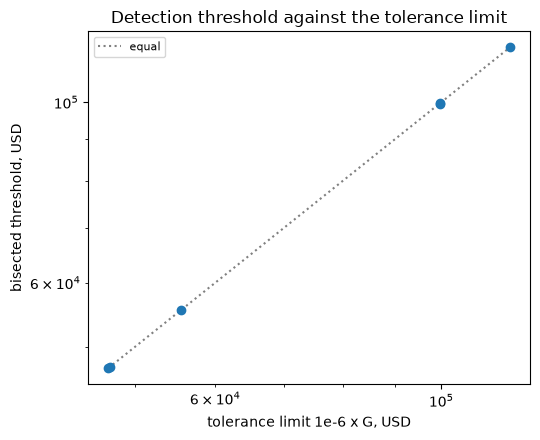

In [5]:
# Bisect the size of one defect to find where the gate starts to name it, on each of the six dates
thresholds = {}
for d, (allow, gca, lines, stage_ecl) in tables.items():
    r0 = c06[d]["outputs"]["reconciliation"]["allowance"][0]
    moves = {m["line_id"]: m["amount"] for m in r0["movements"]}
    low, high = 0.0, 1e8
    for _ in range(60):
        middle = 0.5 * (low + high)
        broken = {**moves, "remeasurement": moves["remeasurement"] + middle}
        row = rec.allowance_rollforward(r0["stage"], r0["opening"], broken, r0["closing"])
        if rec.check_identities([row] + allow[1:], gca, lines, stage_ecl):
            high = middle
        else:
            low = middle
    thresholds[d] = (high, 1e-6 * rec.gross_total(gca))
    print(d, "| smallest defect caught, USD:", round(high, 1), "| limit, USD:", round(thresholds[d][1], 1))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
limits = [v[1] for v in thresholds.values()]
found = [v[0] for v in thresholds.values()]
ax.scatter(limits, found, color="tab:blue", zorder=3)
ax.plot([min(limits), max(limits)], [min(limits), max(limits)], color="grey", linestyle=":", label="equal")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("tolerance limit 1e-6 x G, USD")
ax.set_ylabel("bisected threshold, USD")
ax.set_title("Detection threshold against the tolerance limit")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

On the six dates the bisected threshold sits on the diagonal: a defect is caught exactly from the size of its limit, $10^{-6} \times G$, which goes from 47,124.4 to 116,761.4 USD with the size of the book. The gate is neither blind below its limit nor oversensitive above it, so its power is a known function of the book, and a validator who reports it green should say that it protects against an error of tens of thousands of USD and not against a rounding of a few thousand. Tightening the tolerance moves the threshold in proportion.

### Part 3: overlays are lines, and only the total moves

The cell rebuilds Banco Andino's two overlays as in notebook 04 and passes them to the engine's `portfolio_allowance` with one constructed account per stage that stands for the committed stage ECL, so that the model figures are those of the file. It multiplies the overlays by 0, 1, 10 and 100 and checks the invariance: the model ECL and the ECL by stage never change, and the total allowance changes by exactly the overlay total.

In [6]:
# Scale the overlays of Banco Andino and check that only the overlay total and the total allowance move
detail = c07["base"]["outputs"]["ifrs9_detail"]
row = [t for t in c07["base"]["tests"] if t["test_id"] == "ifrs9.overlay_diagnostics"][0]
split = {amount: target for target, amount in row["extras"]["by_target"].items() if amount}
overlays = [
    ovl.Overlay(id=o["id"], rationale_en=o["label"]["en"], rationale_es=o["label"]["es"], method="expert",
                target=split[o["amount"]], segment_id=o["segment_id"], stage=o["stage"], amount=o["amount"],
                staging_effect="none", review_date="2026-08-31", currency="CLP")  # review date: a lesson input
    for o in detail["overlays"]
]
by_stage = {r["stage"]: r["ecl"] for r in detail["stage_summary"] if r["stage"] != "poci"}
codes = np.array([1, 2, 3])
ecl12, ecl_life, ecl_s3 = (np.array(v) for v in ([by_stage["stage1"], 0.0, 0.0], [0.0, by_stage["stage2"], 0.0],
                                                   [0.0, 0.0, by_stage["stage3"]]))
baseline = ecl_engine.portfolio_allowance(codes, ecl12, ecl_life, ecl_s3, overlays=overlays)
for factor in (0, 1, 10, 100):
    scaled = [dataclasses.replace(o, amount=o.amount * factor) for o in overlays]
    run = ecl_engine.portfolio_allowance(codes, ecl12, ecl_life, ecl_s3, overlays=scaled)
    same = run.model_total == baseline.model_total and run.by_stage == baseline.by_stage
    exact = abs(run.total - (run.model_total + run.overlay_total)) < 1e-6
    print("overlays x", factor, "| model figures unchanged:", "yes" if same else "no")
    print("   overlay total, CLP millions:", round(run.overlay_total / 1e6, 1))
    print("   total moves by exactly the overlays:", "yes" if exact else "no")
print("total allowance, CLP millions:", round(baseline.total / 1e6, 1))

overlays x 0 | model figures unchanged: yes
   overlay total, CLP millions: 0.0
   total moves by exactly the overlays: yes
overlays x 1 | model figures unchanged: yes
   overlay total, CLP millions: 324.1
   total moves by exactly the overlays: yes
overlays x 10 | model figures unchanged: yes
   overlay total, CLP millions: 3241.3
   total moves by exactly the overlays: yes
overlays x 100 | model figures unchanged: yes
   overlay total, CLP millions: 32413.0
   total moves by exactly the overlays: yes
total allowance, CLP millions: 97592.0


With the overlays multiplied by 0, 1, 10 and 100 the model total and the ECL by stage stay equal in every run, and the total allowance moves by exactly the overlay total: 0, 324.1, 3,241.3 and 32,413 million CLP. At the committed amounts the total allowance is 97,592.0 million CLP. The overlays are kept as two lines and never merged into the model ECL, which is the claim: an overlay is an attributed line that changes the total and nothing else, so a validator can add it, remove it or scale it without touching the model it sits on.

### Part 3b: an overlay is tied to its stage

The identities do more than sum. The allowance closing of a stage must equal its stage ECL plus the overlay carried in that stage. The cell takes the 2008 tables of C06, which have no overlay, and invents one of 10 million USD for the lesson. It first leaves the closing as it was and asks `check_identities`; it then carries the overlay in the Stage 1 closing and as a waterfall line and asks again.

In [7]:
# Carry an overlay of 10 million in the Stage 1 closing and ask which identities notice
allow, gca, lines, stage_ecl = tables["2008-12"]
r1 = c06["2008-12"]["outputs"]["reconciliation"]["allowance"][0]
moves = {m["line_id"]: m["amount"] for m in r1["movements"]}
LESSON = ovl.Overlay(id="LESSON", rationale_en="lesson", rationale_es="lección", method="expert", target="pd",
                     segment_id=None, stage=None, amount=10_000_000.0, staging_effect="none",
                     review_date="2026-08-31", currency="USD")
not_carried = rec.check_identities(allow, gca, lines, stage_ecl, overlays=[LESSON])
carried_row = rec.allowance_rollforward("stage1", r1["opening"], {**moves, "overlay-LESSON": LESSON.amount},
                                        r1["closing"] + LESSON.amount)
raised = [dict(l, amount=l["amount"] + LESSON.amount) if l["id"] == "closing" else dict(l) for l in lines]
overlay_line = {"id": "overlay-LESSON", "kind": "overlay", "overlay_id": "LESSON",
                "amount": LESSON.amount, "stage": None}
all_lines = raised + [overlay_line]
carried = rec.check_identities([carried_row] + allow[1:], gca, all_lines, stage_ecl, overlays=[LESSON])
print("overlay not carried in the closing, identities that fail:", len(not_carried))
print("overlay carried in the closing and as a waterfall line, identities that fail:", len(carried))

overlay not carried in the closing, identities that fail: 1
overlay carried in the closing and as a waterfall line, identities that fail: 0


An overlay of 10 million USD that is not carried in the Stage 1 closing makes the identity that ties the closing to the stage ECL and the overlay fail. Carrying it in the closing and as a waterfall line closes every identity again. The tables are therefore consistent with the overlay only when the overlay is where the identities say it is: the gate ties an overlay to its stage, and an adjustment that is booked in the total without a place in the roll-forward is detected as a break and not accepted as a plug.

### Part 4: the non-linearity, reproduced and bounded

Three tests, in two cells. First, the reference example of notebook 03 ($PD^{\mathrm{TTC}} = 2\%$, $\rho = 0.12$, $z = (+1, 0, -2)$, weights $(0.25, 0.5, 0.25)$) through `nonlinearity_test`. Second, the PD-level index of the six C07 segments recomputed from their weighted PD and PD at the mean factor, and the ECL-level index of the six C06 dates recomputed from the weighted ECL and the ECL at the mean path.

In [8]:
# Run the reference example and recompute the indexes of the committed segments and dates
ex_z, ex_w = np.array([1.0, 0.0, -2.0]), np.array([0.25, 0.5, 0.25])
example = ifrs9.nonlinearity_test(0.02, 0.12, ex_z, ex_w, model_id="lesson")
print("reference example: weighted PD and PD at the mean factor, percent:")
print(round(100 * example.extras["pd_weighted"], 3), round(100 * example.extras["pd_at_mean_z"], 3))
print("index:", round(example.metric, 4), "|", LIGHT[example.light.value])
segments = [t for t in c07["base"]["tests"] if t["test_id"] == "ifrs9.nonlinearity"]
pd_indexes = [ecl_engine.non_linearity_index(t["extras"]["pd_weighted"], t["extras"]["pd_at_mean_z"])
              for t in segments]
print("C07 segments: PD-level index, smallest and largest:")
print(round(min(pd_indexes), 3), round(max(pd_indexes), 3))
for d, art in c06.items():
    block = art["outputs"]["non_linearity"]
    index = ecl_engine.non_linearity_index(block["ecl_weighted"], block["ecl_at_mean_path"])
    print(d, "| ECL-level index:", round(index, 5))

reference example: weighted PD and PD at the mean factor, percent:
2.681 1.8
index: 0.4898 | green
C07 segments: PD-level index, smallest and largest:
0.156 0.956
2006-12 | ECL-level index: 0.00211
2008-12 | ECL-level index: 0.02121
2010-12 | ECL-level index: -0.00071
2019-12 | ECL-level index: 0.0232
2020-06 | ECL-level index: 0.01279
2023-06 | ECL-level index: 0.00622


The reference example is reproduced: the weighted PD is 2.681% and the PD at the mean factor 1.800%, an index of 0.4898. On the six C07 segments the PD-level index runs from 0.156 to 0.956. At the ECL level the six C06 dates give 0.00211, 0.02121, -0.00071, 0.0232, 0.01279 and 0.00622: five are at or above zero, and 2010-12 is below, which the engine reads as amber. The statement that the weighted ECL exceeds the average-scenario ECL therefore does not hold on every committed date, and the sweep that follows says where it should hold.

### Part 4b: the sweep

The cell draws 4,000 cases with a fixed seed: a PD between 0.1% and 20% (log-uniform), a correlation between 0.01 and 0.30, two to five scenarios with factors around a random centre between -5 and +1, and weights from a Dirichlet distribution. Each goes through `nonlinearity_test`. It counts the draws whose factors all lie in the convex region $z \ge \Phi^{-1}(PD^{\mathrm{TTC}})/\sqrt{\rho}$, where Jensen's inequality forbids a negative index, the negative indexes in each group and the red lights, and ends with one explicit concave example.

In [9]:
# Draw 4000 seeded cases through the engine's test and split them by the convex region
rng = np.random.default_rng(20261021)
draws = []
for _ in range(4000):
    pd_ttc = float(np.exp(rng.uniform(np.log(0.001), np.log(0.2))))
    rho = float(rng.uniform(0.01, 0.30))
    k = int(rng.integers(2, 6))
    z = rng.normal(rng.uniform(-5.0, 1.0), rng.uniform(0.3, 1.5), k)
    w = rng.dirichlet(np.ones(k))
    result = ifrs9.nonlinearity_test(pd_ttc, rho, z, w)
    convex = bool(np.all(z >= ndtri(pd_ttc) / math.sqrt(rho)))
    error = result.extras["gauss_hermite_error"]
    draws.append((convex, result.metric, float(np.sum(w * z)), result.light.value, error))
convex_draws = [d for d in draws if d[0]]
other_draws = [d for d in draws if not d[0]]
print("draws:", len(draws), "| others:", len(other_draws))
print("all factors in the convex region:", len(convex_draws))
print("convex region: smallest index, negative indexes:", round(min(d[1] for d in convex_draws), 6),
      sum(d[1] < 0 for d in convex_draws))
print("outside it: smallest index, negative indexes, red lights:", round(min(d[1] for d in other_draws), 4),
      sum(d[1] < 0 for d in other_draws), sum(d[3] == "red" for d in other_draws))
small = all(d[4] <= 1e-9 for d in draws)
print("Gauss-Hermite error at most 1e-9 in every draw:", "yes" if small else "no")
concave = ifrs9.nonlinearity_test(0.2, 0.3, np.array([-3.0, -4.0]), np.array([0.5, 0.5]), model_id="lesson")
print("a concave example: index and light:", round(concave.metric, 5), LIGHT[concave.light.value])
print("convex from z:", round(float(ndtri(0.2) / math.sqrt(0.3)), 3))

draws: 4000 | others: 598
all factors in the convex region: 3402
convex region: smallest index, negative indexes: 0.0 0
outside it: smallest index, negative indexes, red lights: -0.12 356 356
Gauss-Hermite error at most 1e-9 in every draw: yes
a concave example: index and light: -0.01319 red
convex from z: -1.537


Of the 4,000 draws, 3,402 have every scenario factor in the convex region, and there the smallest index is 0.0 and none is negative, as Jensen's inequality requires. Of the 598 draws with a factor outside it, 356 have a negative index, down to -0.12, and every one of those is red. The concave example, a PD of 0.2 and a correlation of 0.3 with factors -3 and -4, gives -0.01319, red, and the convex region starts at z = -1.537. The Gauss-Hermite error is at most 1e-9 in every draw. The claim therefore holds with its qualifier: the weighted PD is at least the PD at the mean factor in the convex regime and can be below it outside.

The figure draws the index of every draw against its weighted mean factor, with the convex-region draws in blue and the others in red.

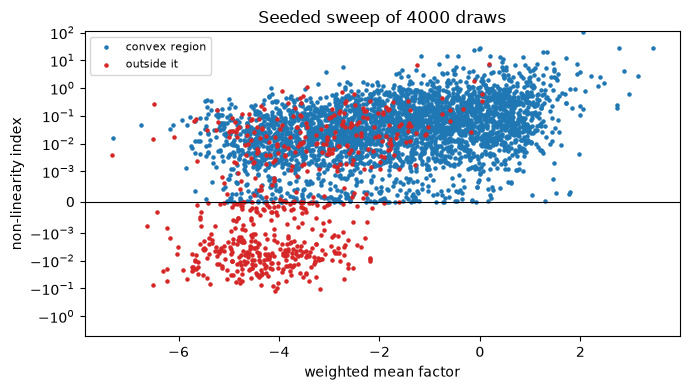

In [10]:
# Draw the non-linearity index of the sweep by the weighted mean factor
fig, ax = plt.subplots(figsize=(7, 4))
for group, color, label in ((convex_draws, "tab:blue", "convex region"), (other_draws, "tab:red", "outside it")):
    ax.scatter([d[2] for d in group], [d[1] for d in group], s=5, color=color, label=label)
ax.axhline(0.0, color="black", linewidth=0.8)
ax.set_yscale("symlog", linthresh=1e-3)
ax.set_xlabel("weighted mean factor")
ax.set_ylabel("non-linearity index")
ax.set_title("Seeded sweep of 4000 draws")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The blue points never fall below the zero line: in the convex region the index is non-negative whatever the PD, the correlation and the weights, because the conditional PD bends upward there. The red points spread on both sides, and the ones below the line are the draws whose scenarios sit on the concave tail of the curve, where the PD flattens and an average of scenarios can exceed a weighted one. The boundary between the two clouds is the property a validator needs to know: the qualifier of the claim is not a hedge but the region where the identity is a theorem.

### Part 5: three regimes, one synthetic bank, a bridge in every scenario

The last test is reconciliation over the six scenarios of Banco Andino. For each file the cell checks that the total of each regime equals the sum of its segments plus the unallocated lines, that the B-1 comparable total plus the additional provisions equals the booked B-1 total, that the B-1 total plus the steps of the bridge equals the IFRS 9 total, and that the file carries the synthetic notice in both languages. It prints the three provisions and the ratio of IFRS 9 to B-1, a statement about the same book under different rules and not about which rule is right.

In [11]:
# Reconcile the totals, the booked B-1 total and the bridge in each of the six scenarios
KEYS = ("cmf_b1_provision", "ifrs9_provision", "bde_annex9_provision")
checks = {"sums": [], "booked": [], "bridge": [], "notice": []}
for name, art in c07.items():
    out = art["outputs"]
    comparison = out["comparison"]
    totals = {k: sum(r[k] for r in comparison["rows"]) + comparison["unallocated"][k] for k in KEYS}
    regimes = {r["regime"]: r["total_provision"] for r in out["regimes"]}
    sums_ok = all(abs(totals[k] - regimes[r]) < 1.0 for k, r in zip(KEYS, ("cmf-b1", "ifrs9", "bde-annex9")))
    extra = out["b1_detail"]["additional_provisions"]["amount"]
    checks["sums"].append(sums_ok)
    checks["booked"].append(abs(out["b1_detail"]["booked_total"] - (regimes["cmf-b1"] + extra)) < 1.0)
    bridge_end = totals[KEYS[0]] + sum(s["amount"] for s in out["gap_bridge"]["steps"])
    checks["bridge"].append(abs(bridge_end - totals[KEYS[1]]) < 1.0)
    checks["notice"].append(bool(out["notice"]["en"]) and bool(out["notice"]["es"]) and out["synthetic"])
    print(f"{SCENARIO[name]:20s} B-1 {regimes['cmf-b1'] / 1e9:7.1f} | IFRS 9 {regimes['ifrs9'] / 1e9:7.1f}")
    residual = abs(bridge_end - totals[KEYS[1]])
    print(f"{'':20s} IFRS 9 over B-1: {regimes['ifrs9'] / regimes['cmf-b1']:6.3f}")
    print(f"{'':20s} bridge residual, CLP: {residual:.2f}")
print("checks that hold in all six scenarios:", len(c07), "scenarios")
for key, values in checks.items():
    print("  ", key, "yes" if all(values) else "no")

base                 B-1   152.0 | IFRS 9    97.6
                     IFRS 9 over B-1:  0.642
                     bridge residual, CLP: 0.00
recession            B-1   197.5 | IFRS 9   169.8
                     IFRS 9 over B-1:  0.860
                     bridge residual, CLP: 0.00
house prices         B-1   168.9 | IFRS 9   128.8
                     IFRS 9 over B-1:  0.763
                     bridge residual, CLP: 0.00
consumer arrears     B-1   178.6 | IFRS 9   126.3
                     IFRS 9 over B-1:  0.707
                     bridge residual, CLP: 0.00
UF inflation         B-1   166.9 | IFRS 9   117.4
                     IFRS 9 over B-1:  0.703
                     bridge residual, CLP: 0.00
combined severe      B-1   275.8 | IFRS 9   327.8
                     IFRS 9 over B-1:  1.189
                     bridge residual, CLP: 0.00
checks that hold in all six scenarios: 6 scenarios
   sums yes
   booked yes
   bridge yes
   notice yes


In all six scenarios the totals equal the sum of their segments plus the unallocated lines, the booked B-1 total equals the comparable total plus the additional provisions, the bridge from B-1 to IFRS 9 closes with a residual of 0.00 CLP, and every file carries the synthetic notice in both languages. IFRS 9 over B-1 runs from 0.642 in the base to 1.189 in the combined severe case. This is a statement of reconciliation and of the order of the regimes on one synthetic book. It is not a validation of any regime, and it says nothing about whether a real bank would be provisioned this way.

## Results

**Answer:** Yes on all four counts: the reconciliation gate closes its 12 identities on six dates, catches each of six planted defects of one million USD, and starts to name a defect exactly at its limit of one millionth of the gross carrying amount (47247.6 USD in 2008-12 and 116761.4 in 2023-06); the overlays change only the total allowance (overlay totals of 0.0, 324.1, 3241.3 and 32413.0 million CLP) while the model figures stay equal; the weighted index is never negative in the convex region (3402 draws, none negative) and is negative in 356 of the 598 draws outside it; and the three regimes of Banco Andino reconcile in all six scenarios with a bridge residual of 0.00 CLP, with IFRS 9 over B-1 running from 0.642 to 1.189.

- **The identities close on six dates.** On every C06 date the twelve identities hold and `check_identities` returns an empty list. The largest residual is 1.5e-05 USD (2006-12 and 2019-12), 1.3e-05 (2020-06), 3.8e-06 (2010-12) and 1.2e-07 (2008-12 and 2023-06), against absolute limits of 47124.4, 47247.6, 55459.9, 99603.2, 99710.5 and 116761.4 USD, one millionth of $G$. The engine's own test is green on all six dates, and the residuals are the rounding of the stored numbers, at least nine orders of magnitude below the limit.
- **The gate catches what it should, and its threshold is the tolerance.** Six defects of 1,000,000 USD are caught, each by one to three identities that carry the defective quantity. The bisection finds on each date that a defect is caught exactly from the size of the limit $10^{-6} \times G$: 47124.4, 47247.6, 55459.9, 99603.2, 99710.5 and 116761.4 USD.
- **Overlays change the total and nothing else.** With the overlays multiplied by 0, 1, 10 and 100 the model figures stay equal, and the total allowance moves by exactly the overlay total. At the committed amounts it is 97592.0 million CLP. An overlay of 10 million USD that is not carried in the Stage 1 closing makes one identity fail, and carrying it in the closing and as a waterfall line closes every identity: the identities tie the overlay to its stage.
- **The non-linearity example is reproduced.** The weighted PD is 2.681% and the PD at the mean factor 1.800%, an index of 0.4898. On the committed C07 segments the PD-level index runs from 0.156 to 0.956.
- **The weighted ECL is not always above the mean-path ECL, and the claim says where it holds.** On the committed C06 dates the ECL-level index is 0.00211, 0.02121, -0.00071, 0.0232, 0.01279 and 0.00622: five of six are at or above zero and 2010-12 is below. The sweep of 4000 seeded draws shows why the statement needs its qualifier: of 3402 draws with every scenario factor in the convex region the smallest index is 0.0 and none is negative; of 598 draws with a factor outside it 356 are negative (down to -0.12) and all of those are red. A concave example gives -0.01319, red, and the convex region starts at z = -1.537.
- **Three regimes reconcile in every scenario.** For the six Banco Andino files the totals equal the sum of their segments plus the unallocated lines, the booked B-1 total equals the comparable total plus the additional provisions, the bridge from B-1 to IFRS 9 closes with a residual of 0.00 CLP, and every file carries the synthetic notice in both languages. IFRS 9 over B-1 runs from 0.642 in the base to 1.189 in the combined severe case.

What the claim says, as the evidence holds it: the roll-forward closes as a gate whose measured threshold is one millionth of the gross carrying amount (not one millionth of a unit of money); overlays are separate lines; the weighted PD is at least the PD at the mean factor in the convex regime; one synthetic bank is provisioned under three regimes with a bridge that reconciles. What it does not claim: that any regime is right, that the committed ECL-level inequality holds on every date (it does not on 2010-12), that Banco Andino resembles a real bank, or that no public comparison of the three regimes exists beyond what the research found.

## Summary

- The claim has four parts, and each is a test on committed files with the engine: the reconciliation gate, the overlay invariance, the non-linearity and the three-regime reconciliation.
- The gate closes on six dates, catches six planted defects by name, and its measured detection threshold is $10^{-6} \times G$, tens of thousands of USD on these books.
- Overlays are lines: changing them moves the total allowance by exactly their amount and moves nothing else; the identities tie each one to its stage.
- The weighted PD is at least the PD at the mean factor in the convex regime and can be below it outside; the committed ECL-level index was below zero once in six dates.
- One synthetic bank under CMF B-1, IFRS 9 and Annex 9 reconciles through a bridge in six scenarios, and the ranking of the regimes changes with the scenario.
- The claim is bounded by its evidence: no regime is validated, the bank is synthetic and the absence of a public comparison is what the research found.

**What to try next.** Plant a defect of your own size in the Stage 3 row and bisect its threshold; scale the overlays by a negative factor and read what `check_identities` says; change the seed of the sweep. The claim text and its evidence are in the SDD's list of claims.

## References

- IASB, IFRS 9 Financial Instruments (July 2014), as endorsed by Commission Regulation (EU) 2016/2067, paragraphs 5.5 and B5.5, and the IFRS 7 amendments 35A to 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 June 2016, sections 2.1.1, 2.7.2 and 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf
- ECB Banking Supervision (2024), IFRS 9 overlays and model improvements for novel risks, July 2024. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.IFRS9novelrisks_202407~5e0eb30b5c.en.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), paragraphs 36, 50 and 51 and annex paragraph A26. https://www.bis.org/bcbs/publ/d350.htm
- BCBS (2005), An explanatory note on the Basel II IRB risk weight functions, section 4.2: the one-factor model. https://www.bis.org/publications/explanatory-note-basel-ii-irb-risk-weight-functions.pdf
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3), 199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- CMF Chile, Compendio de Normas Contables para Bancos (CNCB), Chapters A-2 (N 5) and B-1 (N 2, N 3, N 4 and N 9), Circular 2.346. https://www.cmfchile.cl/portal/normativa/624/articles-29177_doc_pdf.pdf
- Banco de España, Circular 6/2021 of 22 December (BOE-A-2021-21666): the tables of points 140, 144 and 172, applicable from 30 June 2022. https://www.boe.es/buscar/doc.php?id=BOE-A-2021-21666